# EDA & Data visualization

Notebook này phân tích 4 feed nghiệp vụ trong bài toán đối soát:

- **Đơn hàng (OMS)**: `oms_orders.csv`
- **Thanh toán / ngân hàng**: `bank_statement.csv`
- **Vận chuyển (3PL)**: `logistics_report.csv`
- **Ground truth**: `ground_truth.csv` (logic benchmark)

Thư mục chứa dữ liệu: `data/generated/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")

ROOT = Path.cwd()
if not (ROOT / "data" / "generated").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data" / "generated"
assert DATA_DIR.exists(), f"Không tìm thấy thư mục dữ liệu: {DATA_DIR}"

orders = pd.read_csv(DATA_DIR / "oms_orders.csv", parse_dates=["ordered_at"])
payments = pd.read_csv(DATA_DIR / "bank_statement.csv", parse_dates=["txn_date", "value_date"])
shipping = pd.read_csv(DATA_DIR / "logistics_report.csv", parse_dates=["picked_at", "delivered_at"])
truth = pd.read_csv(DATA_DIR / "ground_truth.csv")

tables = {
    "Đơn hàng": orders,
    "Thanh toán": payments,
    "Vận chuyển": shipping,
    "Ground truth": truth,
}
print(f"Data directory: {DATA_DIR.resolve()}")
[(name, frame.shape) for name, frame in tables.items()]

Data directory: C:\Users\teflo\Desktop\WORK\Internship\Projects\Reconciliation Engine\data\generated


[('Đơn hàng', (99441, 8)),
 ('Thanh toán', (98964, 8)),
 ('Vận chuyển', (97114, 10)),
 ('Ground truth', (99441, 9))]

Tổng đơn hàng: 99.441

Ghi nhận:
- Bảng Thanh toán chỉ có 98.964 records, tức thiếu 477 đơn 
- Bảng Vận chuyển: 97.114 records, tức thiếu 2.327 đơn 

## 1. Tổng quan dữ liệu (integrity check)

In [2]:
def quality_report(frame: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "missing_n": frame.isna().sum(),
        "missing_pct": (frame.isna().mean() * 100).round(2),
        "unique_n": frame.nunique(dropna=True),
    }).sort_values(["missing_pct", "unique_n"], ascending=[False, True])

for name, frame in tables.items():
    print(f"\n=== {name}: {frame.shape[0]:,} hàng x {frame.shape[1]} cột ===")
    display(frame.head(3))
    display(quality_report(frame))
    print("Duplicate rows:", int(frame.duplicated().sum()))


=== Đơn hàng: 99,441 hàng x 8 cột ===


,order_id,tracking_no,customer_id,payment_method,currency,order_amount,order_status,ordered_at
0,2e7a8482f6fb09756ca50c10d7bfc047,OLIST-2e7a8482f6fb09756ca50c10d7bfc047,08c5351a6aca1c1589a38f244edeee9d,PREPAID,BRL,136.23,shipped,2016-09-04 21:15:19
1,e5fa5a7210941f7d56d0208e4e071d35,OLIST-e5fa5a7210941f7d56d0208e4e071d35,683c54fc24d40ee9f8a6fc179fd9856c,PREPAID,BRL,75.06,canceled,2016-09-05 00:15:34
2,809a282bbd5dbcabb6f2f724fca862ec,OLIST-809a282bbd5dbcabb6f2f724fca862ec,622e13439d6b5a0b486c435618b2679e,PREPAID,BRL,NaN,canceled,2016-09-13 15:24:19


,dtype,missing_n,missing_pct,unique_n
order_amount,float64,775,0.78,27375
payment_method,object,0,0.00,1
currency,object,0,0.00,1
order_status,object,0,0.00,8
ordered_at,datetime64[ns],0,0.00,98875
order_id,object,0,0.00,99441
tracking_no,object,0,0.00,99441
customer_id,object,0,0.00,99441


Duplicate rows: 0

=== Thanh toán: 98,964 hàng x 8 cột ===


,txn_ref,txn_date,value_date,description,currency,credit_amount,fee_amount,net_amount
0,OLIST-PAY-2e7a8482f6fb09756ca50c10d7bfc047,2016-09-04 21:15:19,2016-10-07,OLIST PAYMENT 2e7a8482f6fb09756ca50c10d7bfc047,BRL,136.23,0.00,136.23
1,OLIST-PAY-e5fa5a7210941f7d56d0208e4e071d35,2016-09-05 00:15:34,2016-10-07,OLIST PAYMENT e5fa5a7210941f7d56d0208e4e071d35,BRL,75.06,0.00,75.06
2,OLIST-PAY-809a282bbd5dbcabb6f2f724fca862ec,2016-09-13 15:24:19,2016-10-07,OLIST PAYMENT 809a282bbd5dbcabb6f2f724fca862ec,BRL,40.95,0.00,40.95


...

,dtype,missing_n,missing_pct,unique_n
currency,object,0,0.00,1
cod_collected,float64,0,0.00,1
cod_fee,float64,0,0.00,1
status,object,0,0.00,2
ship_fee,float64,1,0.00,7633
picked_at,datetime64[ns],2,0.00,80605
delivered_at,datetime64[ns],0,0.00,95547
tracking_code,object,0,0.00,97114
client_order_code,object,0,0.00,97114
remittance_id,object,0,0.00,97114


Duplicate rows: 0

=== Ground truth: 99,441 hàng x 9 cột ===


,unit_id,scenario,sub_kind,expected_outcome,expected_exception,payment_method,order_id,tracking_no,bank_txn_ref
0,1,MATCHED,MATCHED,PASS_1,NaN,PREPAID,2e7a8482f6fb09756ca50c10d7bfc047,OLIST-2e7a8482f6fb09756ca50c10d7bfc047,OLIST-PAY-2e7a8482f6fb09756ca50c10d7bfc047
1,2,STATUS_PENDING_POLICY,STATUS_PENDING_POLICY,REVIEW,ORDER_STATUS_REQUIRES_POLICY,PREPAID,e5fa5a7210941f7d56d0208e4e071d35,OLIST-e5fa5a7210941f7d56d0208e4e071d35,OLIST-PAY-e5fa5a7210941f7d56d0208e4e071d35
2,3,INCOMPLETE_SOURCE,INCOMPLETE_SOURCE,REVIEW,MISSING_SOURCE_EVIDENCE,PREPAID,809a282bbd5dbcabb6f2f724fca862ec,OLIST-809a282bbd5dbcabb6f2f724fca862ec,OLIST-PAY-809a282bbd5dbcabb6f2f724fca862ec


,dtype,missing_n,missing_pct,unique_n
expected_exception,object,95659,96.20,5
bank_txn_ref,object,476,0.48,98965
payment_method,object,0,0.00,1
expected_outcome,object,0,0.00,3
scenario,object,0,0.00,6
sub_kind,object,0,0.00,6
unit_id,int64,0,0.00,99441
order_id,object,0,0.00,99441
tracking_no,object,0,0.00,99441


Duplicate rows: 0


- Bảng Đơn hàng: 99.441 dòng - đủ 99.441 giá trị unique của Order_ID
- Bảng Thanh toán: đủ 98.964 giá trị unique của txn_ref
- Bảng Vận chuyển: đủ 97.114 giá trị unique của tracking_code

Không có bản ghi trùng lặp, mỗi đơn tương ứng 1 bản ghi duy nhất. 

In [3]:
# Kiểm tra số lượng kịch bản kiểm tra trong tập ground truth
truth["scenario"].value_counts()

scenario
MATCHED                  95659
STATUS_PENDING_POLICY     1082
AMOUNT_ERROR               977
INCOMPLETE_SOURCE          776
MISSING_PAYMENT            476
MISSING_SHIPMENT           471
Name: count, dtype: int64

In [4]:
numeric_columns = {
    "Đơn hàng": ["order_amount"],
    "Thanh toán": ["credit_amount", "fee_amount", "net_amount"],
    "Vận chuyển": ["cod_collected", "ship_fee", "cod_fee"],
}
for name, columns in numeric_columns.items():
    print(f"\nThống kê số liệu - {name}")
    display(tables[name][columns].describe().T)

print("\nDuplicate key checks")
print("orders.order_id unique:", orders["order_id"].is_unique)
print("payments.txn_ref unique:", payments["txn_ref"].is_unique)
print("shipping.tracking_code unique:", shipping["tracking_code"].is_unique)
print("truth.unit_id unique:", truth["unit_id"].is_unique)


Thống kê số liệu - Đơn hàng


,count,mean,std,min,25%,50%,75%,max
order_amount,"98,666.00",160.58,220.47,9.59,61.98,105.29,176.87,"13,664.08"



Thống kê số liệu - Thanh toán


,count,mean,std,min,25%,50%,75%,max
credit_amount,"98,964.00",161.11,222.26,0.00,62.01,105.33,177.01,"13,664.08"
fee_amount,"98,964.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00
net_amount,"98,964.00",161.11,222.26,0.00,62.01,105.33,177.01,"13,664.08"



Thống kê số liệu - Vận chuyển


,count,mean,std,min,25%,50%,75%,max
cod_collected,"97,114.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00
ship_fee,"97,113.00",22.79,21.50,0.00,13.86,17.19,24.03,"1,794.96"
cod_fee,"97,114.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00



Duplicate key checks
orders.order_id unique: True
payments.txn_ref unique: True
shipping.tracking_code unique: True
truth.unit_id unique: True


### Giá trị đơn:
Mean = 160; Median = 105: Phân bố giá trị đơn lệch phải

Min = 10; **Max = 13664**; std = 220 : Một số đơn có giá trị cực lớn, kéo lệch mean 

### Phí vận chuyển:
min = 0; **max = 1795**; std = 22


## 2. EDA 

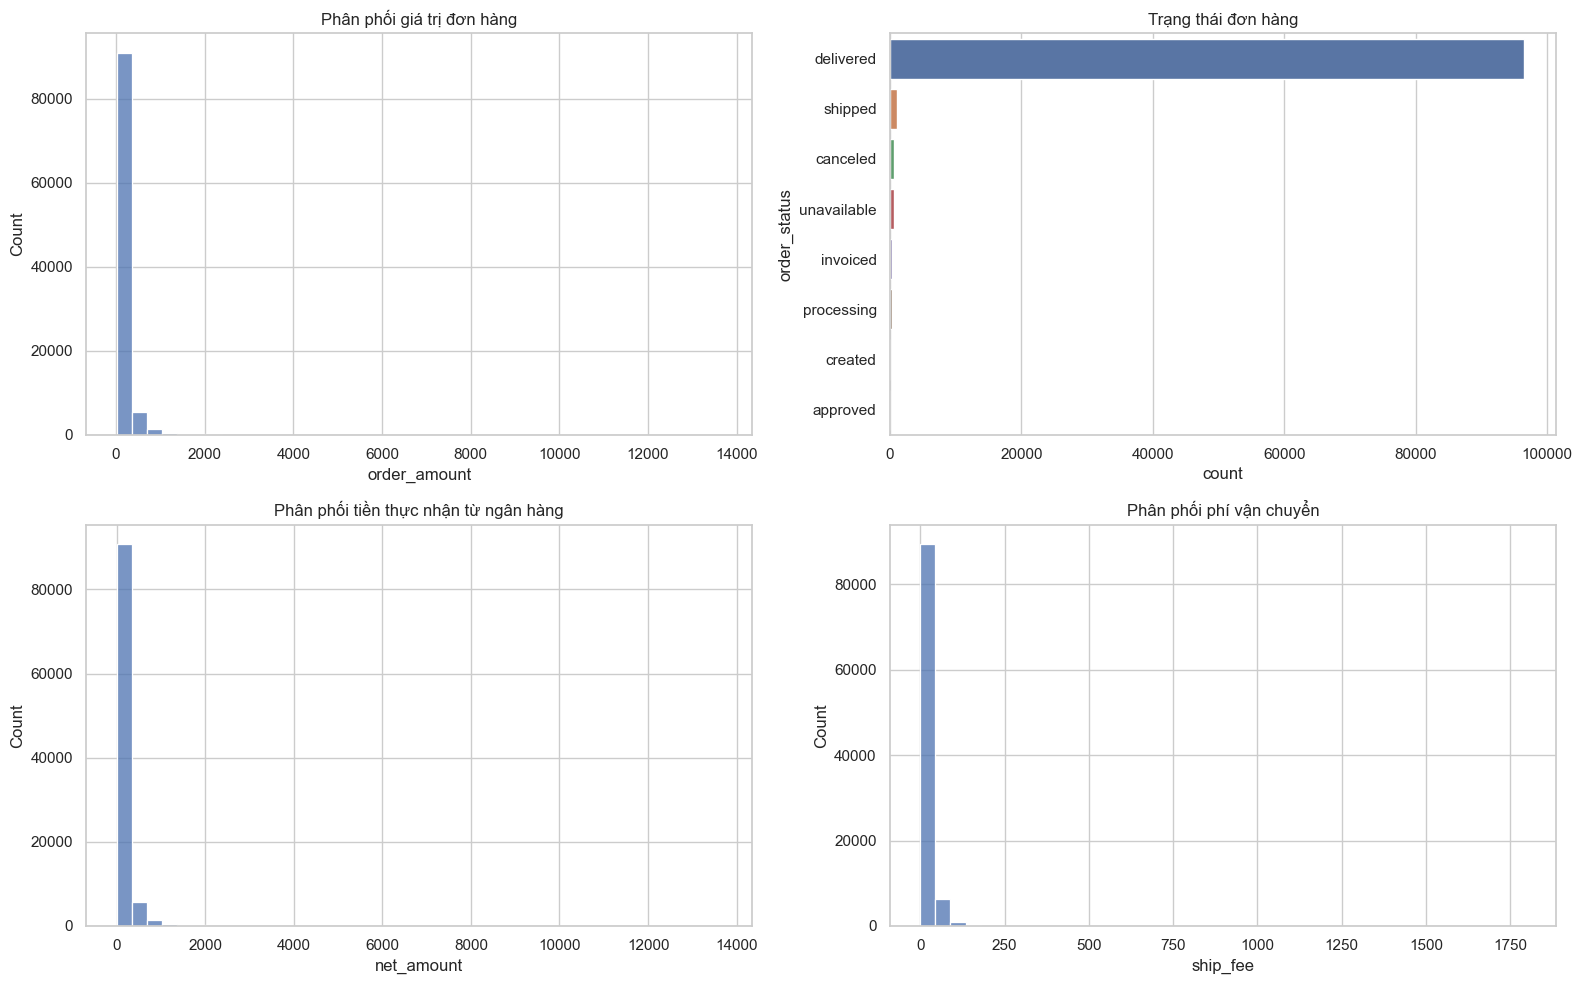

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
sns.histplot(orders, x="order_amount", bins=40, ax=axes[0, 0])
axes[0, 0].set_title("Phân phối giá trị đơn hàng")
sns.countplot(data=orders, y="order_status", order=orders["order_status"].value_counts().index, ax=axes[0, 1])
axes[0, 1].set_title("Trạng thái đơn hàng")
sns.histplot(payments, x="net_amount", bins=40, ax=axes[1, 0])
axes[1, 0].set_title("Phân phối tiền thực nhận từ ngân hàng")
sns.histplot(shipping, x="ship_fee", bins=40, ax=axes[1, 1])
axes[1, 1].set_title("Phân phối phí vận chuyển")
plt.tight_layout()
plt.show()

### Nhận định

- 97% đơn: Delivered; 3% đơn: shipped (đã gửi, chưa nhận), canceled (hủy), unavailable (không rõ), invoiced (đã thanh toán), processing (đang xử lý). 
- `order_id` ở bảng Đơn hàng trùng với phần đuôi của `description` ở bảng Thanh toán
- `tracking_code` = "OLIST-" + `client_order_code`

Mọi giao dịch bank và mọi đơn đều map đượv về bảng Đơn hàng. 

### phân bố của 99% records:

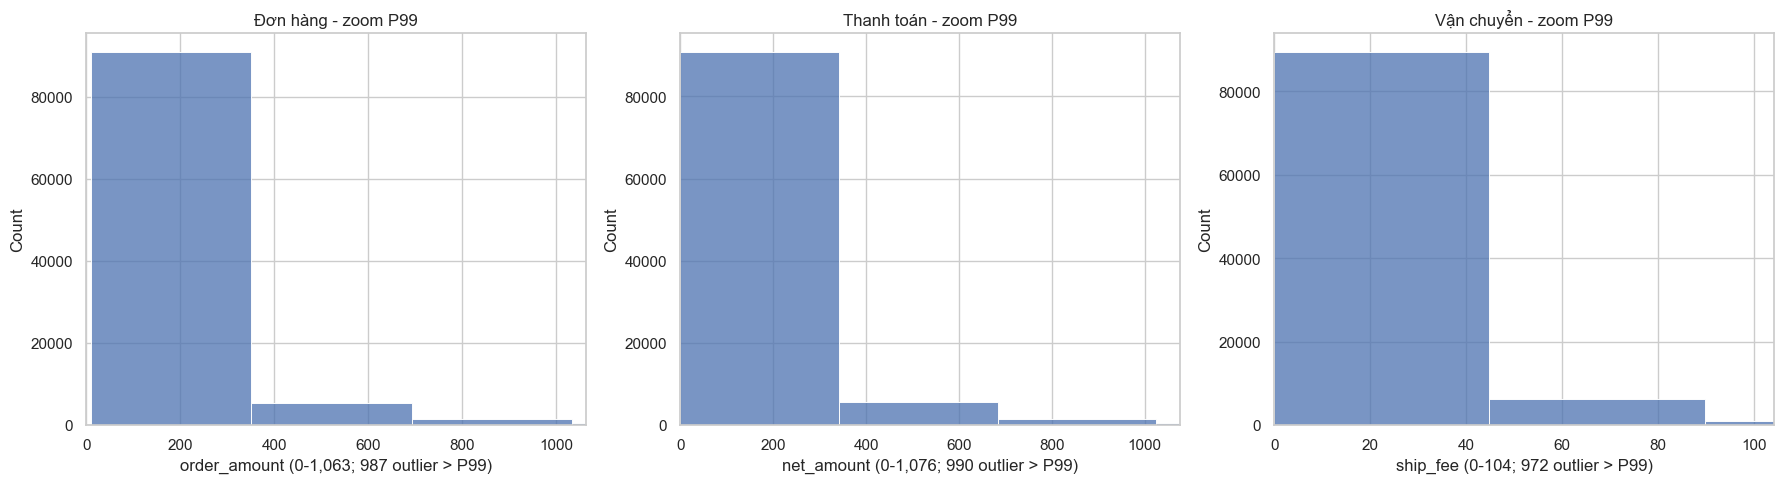

In [6]:
def percentile_xlim(frame, column, percentile=0.99):
    values = frame[column].dropna()
    upper = values.quantile(percentile)
    return (0, upper), int((values > upper).sum())

orders_xlim, orders_outliers = percentile_xlim(orders, "order_amount")
payments_xlim, payments_outliers = percentile_xlim(payments, "net_amount")
shipping_xlim, shipping_outliers = percentile_xlim(shipping, "ship_fee")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(orders, x="order_amount", bins=40, ax=axes[0])
axes[0].set_xlim(orders_xlim)
axes[0].set_xlabel(f"order_amount (0-{orders_xlim[1]:,.0f}; {orders_outliers:,} outlier > P99)")
axes[0].set_title("Đơn hàng - zoom P99")
sns.histplot(payments, x="net_amount", bins=40, ax=axes[1])
axes[1].set_xlim(payments_xlim)
axes[1].set_xlabel(f"net_amount (0-{payments_xlim[1]:,.0f}; {payments_outliers:,} outlier > P99)")
axes[1].set_title("Thanh toán - zoom P99")
sns.histplot(shipping, x="ship_fee", bins=40, ax=axes[2])
axes[2].set_xlim(shipping_xlim)
axes[2].set_xlabel(f"ship_fee (0-{shipping_xlim[1]:,.0f}; {shipping_outliers:,} outlier > P99)")
axes[2].set_title("Vận chuyển - zoom P99")
plt.tight_layout()
plt.show()

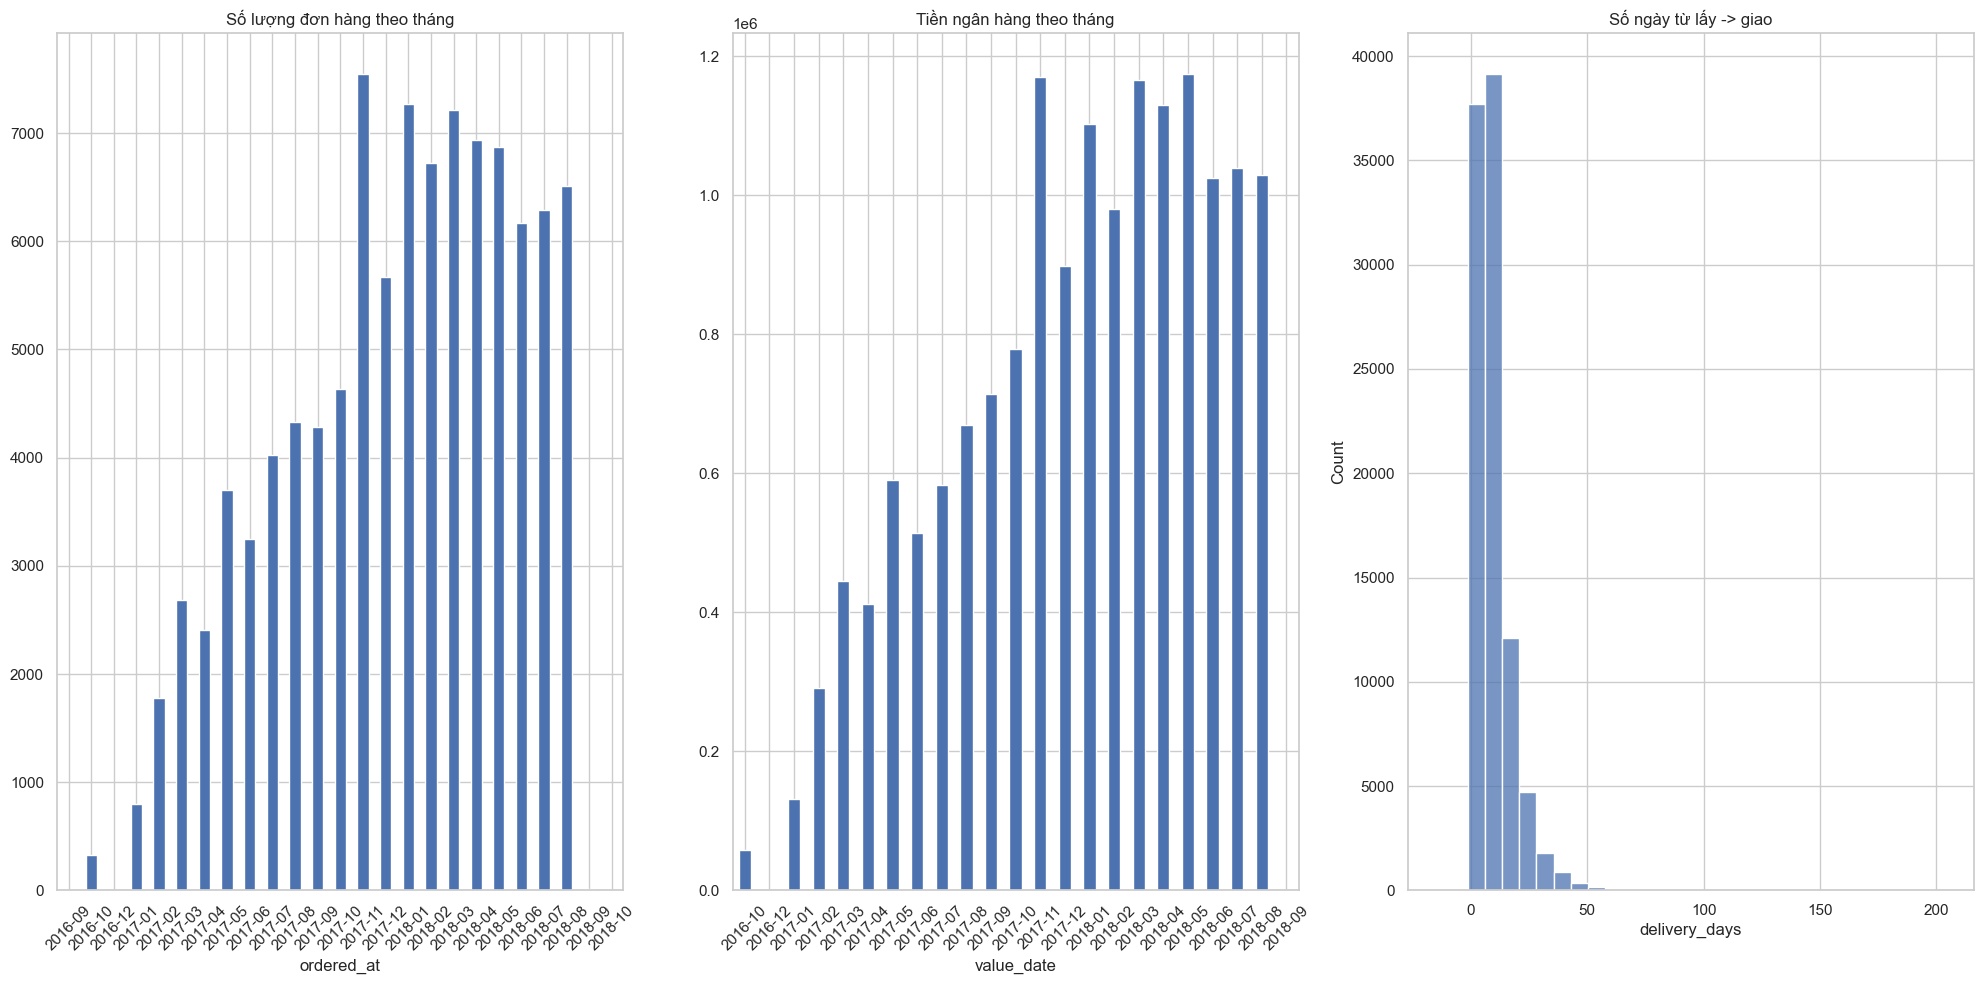

Phương thức thanh toán trong OMS:


,orders
payment_method,
PREPAID,99441


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(20, 10))
orders.groupby(orders["ordered_at"].dt.to_period("M"), observed=False).size().plot(kind="bar", ax=axes[0], title="Số lượng đơn hàng theo tháng")
payments.groupby(payments["value_date"].dt.to_period("M"), observed=False)["net_amount"].sum().plot(kind="bar", ax=axes[1], title="Tiền ngân hàng theo tháng")
shipping["delivery_days"] = (shipping["delivered_at"] - shipping["picked_at"]).dt.total_seconds() / 86400
sns.histplot(shipping.dropna(subset=["delivery_days"]), x="delivery_days", bins=30, ax=axes[2])
axes[2].set_title("Số ngày từ lấy -> giao")
for ax in axes[:2]:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

print("Phương thức thanh toán trong OMS:")
display(orders["payment_method"].value_counts(dropna=False).rename_axis("payment_method").to_frame("orders"))

## 3. Coverage & liên kết giữa 4 feed

- `txn_ref` có dạng `OLIST-PAY-{order_id}`.
- `client_order_code` chính là `order_id`.
- Mỗi record ngân hàng và vận chuyển được thiết kế gắn với tối đa một đơn. 

-> Đối chiếu các `ID` này với `orders.order_id`



In [8]:
orders_keys = set(orders["order_id"])
# Chuan hoa khoa lien ket cua tung feed.
payment_order_ids = payments["txn_ref"].str.removeprefix("OLIST-PAY-")
shipping_order_ids = shipping["client_order_code"].astype(str)
coverage = pd.DataFrame({
    "factor": [
        "Đơn có bank record",
        "Đơn hàng có shipping record",
        "Bank record không map được order",
        "Shipping record không map được order",
        "OMS order không có ground truth",
    ],
    "quantity": [
        orders["order_id"].isin(set(payment_order_ids)).sum(),
        orders["order_id"].isin(set(shipping_order_ids)).sum(),
        (~payment_order_ids.isin(orders_keys)).sum(),
        (~shipping_order_ids.isin(orders_keys)).sum(),
        (~orders["order_id"].isin(truth["order_id"])).sum(),
    ],
    "total_sample": [len(orders), len(orders), len(payments), len(shipping), len(orders)],
})
coverage["percentage"] = coverage["quantity"] / coverage["total_sample"] * 100
display(coverage)

,factor,quantity,total_sample,percentage
0,Đơn có bank record,98964,99441,99.52
1,Đơn hàng có shipping record,97114,99441,97.66
2,Bank record không map được order,0,98964,0.00
3,Shipping record không map được order,0,97114,0.00
4,OMS order không có ground truth,0,99441,0.00


In [9]:
# Bank feed integrity: map 1-1, duplicate, reference format, currency & timeline.
bank_checks = payments.copy()
bank_checks["order_id_from_ref"] = bank_checks["txn_ref"].str.extract(r"^(?:OLIST-PAY-)([0-9a-f]{32})$", expand=False)
bank_checks["txn_ref_missing"] = bank_checks["txn_ref"].isna() | bank_checks["txn_ref"].eq("")
bank_checks["txn_ref_valid_format"] = bank_checks["order_id_from_ref"].notna()
bank_checks["exact_duplicate"] = bank_checks.duplicated(keep=False)
bank_checks["currency_match"] = bank_checks["currency"].eq(orders["currency"].dropna().mode().iat[0])
bank_checks["txn_date"] = pd.to_datetime(bank_checks["txn_date"], errors="coerce")
bank_checks["value_date"] = pd.to_datetime(bank_checks["value_date"], errors="coerce")
bank_with_order = bank_checks.merge(
    orders[["order_id", "ordered_at"]], left_on="order_id_from_ref", right_on="order_id", how="left"
)
bank_with_order["txn_date_reasonable"] = (
    bank_with_order["txn_date"].notna()
    & bank_with_order["ordered_at"].notna()
    & bank_with_order["txn_date"].dt.normalize().ge(bank_with_order["ordered_at"].dt.normalize())
    & bank_with_order["value_date"].notna()
    & bank_with_order["value_date"].dt.normalize().ge(bank_with_order["txn_date"].dt.normalize())
)
txn_ref_mapping = bank_checks.groupby("txn_ref", dropna=False)["order_id_from_ref"].nunique(dropna=True)
bank_integrity = pd.DataFrame({
    "chi_tieu": [
        "Bank record map nhieu order",
        "Txn_ref bi trung",
        "Txn_ref thieu",
        "Txn_ref sai format",
        "Currency khong khop OMS",
        "Ngay giao dich khong hop ly",
    ],
    "so_luong": [
        int((txn_ref_mapping > 1).sum()),
        int(bank_checks["txn_ref"].duplicated(keep=False).sum()),
        int(bank_checks["txn_ref_missing"].sum()),
        int((~bank_checks["txn_ref_valid_format"]).sum()),
        int((~bank_checks["currency_match"]).sum()),
        int((~bank_with_order["txn_date_reasonable"]).sum()),
    ],
    "mau_so": [len(bank_checks)] * 6,
})
bank_integrity["ty_le_pct"] = bank_integrity["so_luong"] / bank_integrity["mau_so"] * 100
display(bank_integrity)

,chi_tieu,so_luong,mau_so,ty_le_pct
0,Bank record map nhieu order,0,98964,0.00
1,Txn_ref bi trung,0,98964,0.00
2,Txn_ref thieu,0,98964,0.00
3,Txn_ref sai format,0,98964,0.00
4,Currency khong khop OMS,0,98964,0.00
5,Ngay giao dich khong hop ly,160,98964,0.16


### Integrity bank
- Kiểm tra 1 Bank record - cover nhiều order: 0
- Kiểm tra txn_ref bị trùng, thiếu, sai format: 0 
- Kiểm tra currency có trùng nhau để thực hiện chuẩn hóa giữa các feed: 0
- Kiểm tra chênh lệch ngày/thời điểm giao dịch: 160 

In [10]:
# Phan biet nhieu giao dich hop le voi duplicate tren cung mot order.
bank_by_order = bank_checks.dropna(subset=["order_id_from_ref"]).groupby("order_id_from_ref").agg(
    bank_record_count=("txn_ref", "size"),
    bank_unique_txn_count=("txn_ref", "nunique"),
    bank_exact_duplicate_count=("exact_duplicate", "sum"),
).reset_index(names="order_id")
bank_by_order["multiple_valid_transactions"] = (
    (bank_by_order["bank_record_count"] > 1)
    & (bank_by_order["bank_unique_txn_count"] == bank_by_order["bank_record_count"])
)
bank_by_order["duplicate_records"] = bank_by_order["bank_exact_duplicate_count"] > 1
display(bank_by_order[bank_by_order["bank_record_count"] > 1].head(20))

,order_id,bank_record_count,bank_unique_txn_count,bank_exact_duplicate_count,multiple_valid_transactions,duplicate_records


### Kiểm tra có order nào được chia nhỏ thành nhiều lần giao dịch hay không

Kết quả hiển thị không có order nào có từ 2 bank records trở lên. (multiple_valid_transactions = True). 

Nếu xuất hiện nhiều txn_ref khác nhau: cần nghiệp vụ xác định đây là split payment? 

Nếu duplicate_records = True: kiểm tra liệu có xuất hiện duplicate - cần nghiệp vụ kiểm tra. 

In [11]:
# Trang thai nao can payment/shipping va ket qua coverage cua tung nhom.
evidence_by_order = orders[["order_id", "order_status"]].drop_duplicates("order_id").merge(
    bank_by_order[["order_id", "bank_record_count"]], on="order_id", how="left"
).merge(
    shipping.groupby("client_order_code").size().rename("shipping_record_count"),
    left_on="order_id", right_index=True, how="left",
)
evidence_by_order["has_bank"] = evidence_by_order["bank_record_count"].fillna(0).gt(0)
evidence_by_order["has_shipping"] = evidence_by_order["shipping_record_count"].fillna(0).gt(0)
shipping_expected = {"shipped", "delivered"}
evidence_by_order["shipping_policy_bucket"] = "NOT_APPLICABLE"
evidence_by_order.loc[evidence_by_order["order_status"].isin(shipping_expected), "shipping_policy_bucket"] = "EXPECTED"
evidence_by_order.loc[
    ~evidence_by_order["has_shipping"] & evidence_by_order["order_status"].isin(shipping_expected),
    "shipping_policy_bucket",
] = "UNEXPECTED_MISSING"
evidence_by_order.loc[
    ~evidence_by_order["order_status"].isin(shipping_expected), "shipping_policy_bucket"
] = "PENDING_POLICY"
status_coverage = evidence_by_order.groupby("order_status").agg(
    orders=("order_id", "size"),
    orders_with_bank=("has_bank", "sum"),
    orders_with_shipping=("has_shipping", "sum"),
    pending_policy=("shipping_policy_bucket", lambda values: (values == "PENDING_POLICY").sum()),
    unexpected_missing_shipping=("shipping_policy_bucket", lambda values: (values == "UNEXPECTED_MISSING").sum()),
).reset_index()
status_coverage["bank_coverage_pct"] = status_coverage["orders_with_bank"] / status_coverage["orders"] * 100
status_coverage["shipping_coverage_pct"] = status_coverage["orders_with_shipping"] / status_coverage["orders"] * 100
display(status_coverage.sort_values("orders", ascending=False))

,order_status,orders,orders_with_bank,orders_with_shipping,pending_policy,unexpected_missing_shipping,bank_coverage_pct,shipping_coverage_pct
3,delivered,96478,96004,96014,0,464,99.51,99.52
6,shipped,1107,1104,1100,0,7,99.73,99.37
1,canceled,625,625,0,625,0,100.00,0.00
7,unavailable,609,609,0,609,0,100.00,0.00
4,invoiced,314,314,0,314,0,100.00,0.00
5,processing,301,301,0,301,0,100.00,0.00
2,created,5,5,0,5,0,100.00,0.00
0,approved,2,2,0,2,0,100.00,0.00


### Coverage theo trạng thái đơn hàng

- delivered và shipped: cần shipping evidence; thiếu shipping trong 2 nhóm này: Unexpected_missing
- Các trạng thái canceled, unavailable, created, processing, invoiced, approved: Pending_policy, chờ nghiệp vụ quyết định có cần payment/shipping không

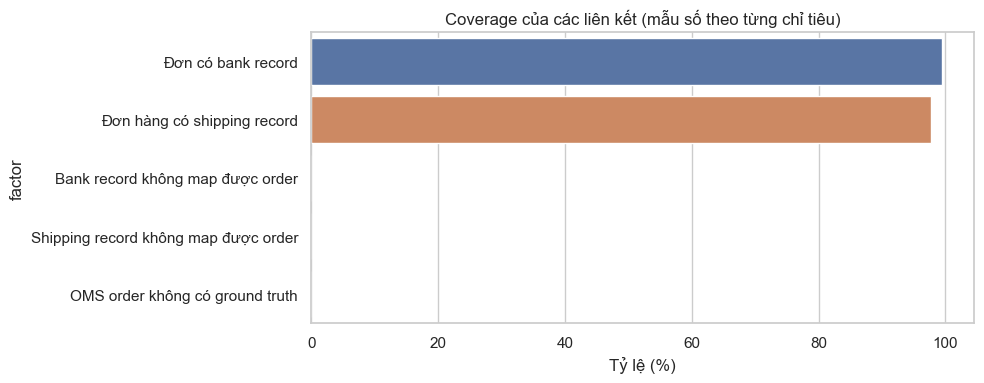

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=coverage, x="percentage", y="factor", ax=ax)
ax.set_title("Coverage của các liên kết (mẫu số theo từng chỉ tiêu)")
ax.set_xlabel("Tỷ lệ (%)")
plt.tight_layout()
plt.show()

### Visualization coverage

Biểu đồ giúp so sánh nhanh tỷ lệ giữa các chỉ tiêu, nhưng vẫn cần đọc cùng bảng số lượng và mẫu số ở chunk 1. Đặc biệt, tỷ lệ map của bank hoặc shipping là tỉ lệ trên feed tương ứng, còn tỷ lệ order có evidence là tỷ lệ trên OMS; chúng không hoàn toàn cùng một câu hỏi nghiệp vụ.

Có 99441 - 98964 = `477` đơn từ OMS không có bank record. 

Có 99441 - 97114 = `2.327` đơn OMS không có ship record.

,records
scenario,
MATCHED,95659
STATUS_PENDING_POLICY,1082
AMOUNT_ERROR,977
INCOMPLETE_SOURCE,776
MISSING_PAYMENT,476
MISSING_SHIPMENT,471


,records
exception,
NONE,95659
ORDER_STATUS_REQUIRES_POLICY,1082
AMOUNT_MISMATCH,977
MISSING_SOURCE_EVIDENCE,776
MISSING_PAYMENT,476
MISSING_SHIPMENT,471


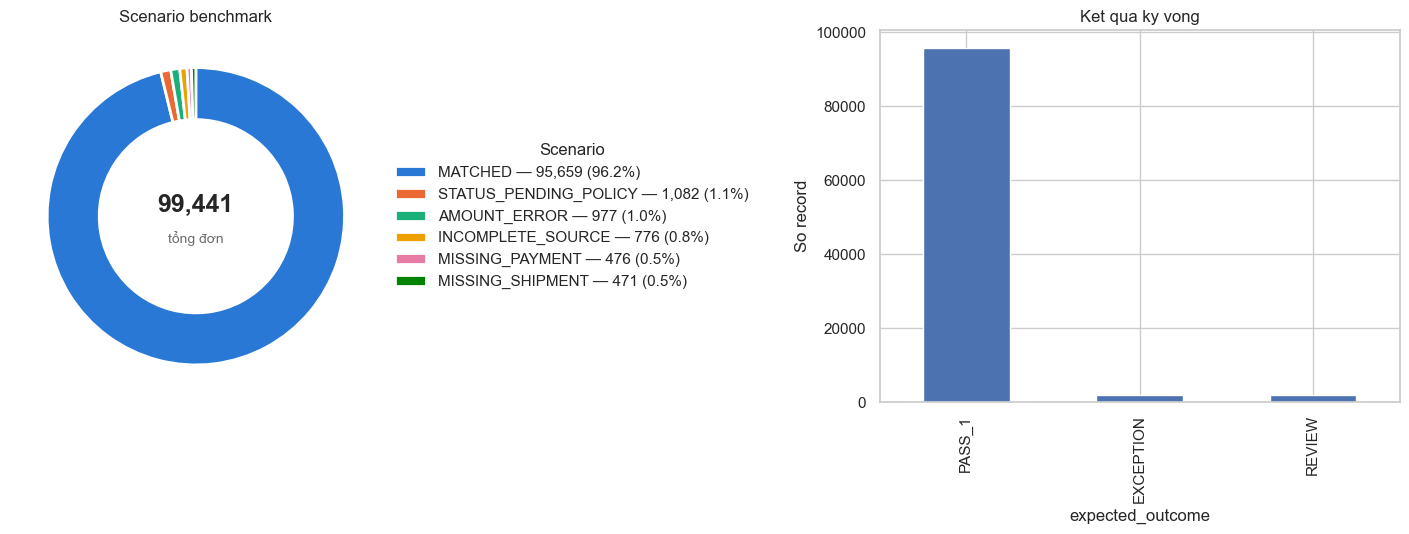

In [13]:
display(truth["scenario"].value_counts(dropna=False).rename_axis("scenario").to_frame("records"))
display(truth["expected_exception"].fillna("NONE").value_counts().rename_axis("exception").to_frame("records"))

scenario_counts = truth["scenario"].value_counts()
scenario_pct = scenario_counts / scenario_counts.sum() * 100
# Mau co dinh theo scenario (khong theo thu hang) de cac bieu do khac dung lai duoc
SCENARIO_COLORS = {
    "MATCHED": "#2a78d6",
    "STATUS_PENDING_POLICY": "#eb6834",
    "AMOUNT_ERROR": "#1baf7a",
    "INCOMPLETE_SOURCE": "#eda100",
    "MISSING_PAYMENT": "#e87ba4",
    "MISSING_SHIPMENT": "#008300",
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
wedges, _ = axes[0].pie(
    scenario_counts, colors=[SCENARIO_COLORS[s] for s in scenario_counts.index],
    startangle=90, counterclock=False,
    wedgeprops={"width": 0.35, "edgecolor": "white", "linewidth": 2},
)
axes[0].text(0, 0.08, f"{scenario_counts.sum():,}", ha="center", va="center", fontsize=18, fontweight="bold")
axes[0].text(0, -0.15, "tổng đơn", ha="center", va="center", fontsize=10, color="dimgray")
axes[0].legend(
    wedges,
    [f"{s} — {n:,} ({p:.1f}%)" for s, n, p in zip(scenario_counts.index, scenario_counts, scenario_pct)],
    title="Scenario", loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False,
)
axes[0].set_title("Scenario benchmark")
axes[0].set_aspect("equal")

truth["expected_outcome"].value_counts().plot.bar(ax=axes[1], title="Ket qua ky vong")
axes[1].set_ylabel("So record")
plt.tight_layout()
plt.show()


## 4. Tạo bảng đối chiếu và đo lường sai lệch

Trong feed mẫu, `description` của bank chứa `order_id` và `tracking_code` của logistics trùng với `tracking_no` OMS. Trong hệ thống thật, nen ưu tiên khóa chuẩn hóa (reference ID / tracking code), sau đó mới dùng fuzzy matching.

### Phễu đối soát

Mỗi bước chỉ xét các đơn **chưa được bước trước quyết định**, gán một kết quả, phần còn lại chuyển sang bước sau. Thứ tự đi từ "có đủ điều kiện để đối soát không" (dữ liệu nguồn, trạng thái) đến "bằng chứng có khớp không" (thanh toán, số tiền, vận chuyển). Cột `scenario` trong mỗi bảng phân rã là ground truth, dùng để kiểm tra bước đó có gán đúng không.

In [14]:
# Bang doi chieu: moi dong la 1 don OMS, gan them bang chung tu bank va logistics
recon = orders.merge(
    truth[["order_id", "scenario", "expected_outcome", "expected_exception"]],
    on="order_id", how="left", validate="one_to_one",
)
payment_view = payments.copy()
payment_view["order_id"] = payment_view["txn_ref"].str.removeprefix("OLIST-PAY-")
payment_view = payment_view.groupby("order_id", as_index=False).agg(
    bank_credit=("credit_amount", "sum"), bank_fee=("fee_amount", "sum"), bank_net=("net_amount", "sum"), bank_txn_count=("txn_ref", "nunique")
)
shipping_view = shipping.groupby("client_order_code", as_index=False).agg(
    cod_collected=("cod_collected", "sum"), ship_fee=("ship_fee", "sum"), cod_fee=("cod_fee", "sum"),
    shipping_status=("status", "last"), shipping_event_count=("tracking_code", "nunique")
).rename(columns={"client_order_code": "order_id"})
recon = recon.merge(payment_view, on="order_id", how="left", validate="one_to_one")
recon = recon.merge(shipping_view, on="order_id", how="left", validate="one_to_one")
recon["payment_delta"] = recon["bank_net"] - recon["order_amount"]
recon["has_payment"] = recon["bank_txn_count"].fillna(0).gt(0)
recon["has_shipment"] = recon["shipping_event_count"].fillna(0).gt(0)

AMOUNT_TOLERANCE = 0.01  # BRL
SETTLEABLE_STATUSES = {"delivered", "shipped"}
recon["simple_rule"] = pd.NA  # NA = chua duoc buoc nao quyet dinh
funnel = {}


def apply_step(step, condition, label):
    """Gan label cho cac don CHUA co ket qua va thoa condition; in phan ra theo ground truth va trang thai."""
    pending = recon["simple_rule"].isna()
    hit = pending & condition
    recon.loc[hit, "simple_rule"] = label
    funnel[step] = {"ket_qua": label, "dau_vao": int(pending.sum()), "so_don": int(hit.sum()), "con_lai": int((pending & ~condition).sum())}
    print(f"{step}: {funnel[step]['dau_vao']:,} don dau vao -> {funnel[step]['so_don']:,} {label} | con lai {funnel[step]['con_lai']:,}")
    display(pd.concat({
        "scenario (ground truth)": recon.loc[hit, "scenario"].value_counts(),
        "order_status": recon.loc[hit, "order_status"].value_counts(),
    }).rename("so_don").to_frame())
    return hit


print(f"Tong don OMS: {len(recon):,}")

Tong don OMS: 99,441


In [15]:
# Buoc 1 - Du lieu nguon: khong co order_amount thi khong co gi de so voi tien ngan hang
step1 = apply_step("1. Du lieu nguon", recon["order_amount"].isna(), "MISSING_SOURCE_EVIDENCE")
print("Trong so nay: co bank record =", int(recon.loc[step1, "has_payment"].sum()), "| co van don =", int(recon.loc[step1, "has_shipment"].sum()))

1. Du lieu nguon: 99,441 don dau vao -> 775 MISSING_SOURCE_EVIDENCE | con lai 98,666


so_don
scenario (ground truth) INCOMPLETE_SOURCE     775
order_status            unavailable           603
                        canceled              164
                        created                 5
                        invoiced                2
                        shipped                 1

Trong so nay: co bank record = 775 | co van don = 1


**Nhận định — bước 1**
- 775 đơn thiếu `order_amount`, 100% thuộc `INCOMPLETE_SOURCE` → bước gán đúng hoàn toàn.
- Chủ yếu là `unavailable` (603) và `canceled` (164): đơn không có item nên OMS không tính được giá trị.
- Cả 775 đơn **vẫn có tiền về ngân hàng** nhưng gần như không có vận đơn (1 đơn) → tiền đã thu cho một đơn không xác định được giá trị.

**Quyết định tiếp theo**
- Loại 775 đơn khỏi phễu, đưa vào hàng chờ `REVIEW` — không thể so khớp số tiền khi thiếu một vế.
- Nghiệp vụ cần tra lại item/giá trị đơn từ hệ thống nguồn; nếu đơn bị hủy thì đối chiếu với giao dịch hoàn tiền.
- 98.666 đơn còn lại có đủ giá trị → sang bước 2.

In [16]:
# Buoc 2 - Trang thai: chi delivered/shipped moi du dieu kien doi soat payment + shipping
step2 = apply_step("2. Trang thai don", ~recon["order_status"].isin(SETTLEABLE_STATUSES), "ORDER_STATUS_REQUIRES_POLICY")
print("Trong so nay: co bank record =", int(recon.loc[step2, "has_payment"].sum()), "| co van don =", int(recon.loc[step2, "has_shipment"].sum()))

2. Trang thai don: 98,666 don dau vao -> 1,082 ORDER_STATUS_REQUIRES_POLICY | con lai 97,584


so_don
scenario (ground truth) STATUS_PENDING_POLICY    1082
order_status            canceled                  461
                        invoiced                  312
                        processing                301
                        unavailable                 6
                        approved                    2

Trong so nay: co bank record = 1082 | co van don = 0


**Nhận định — bước 2**
- 1.082 đơn ở trạng thái `canceled` (461), `invoiced` (312), `processing` (301), `unavailable` (6), `approved` (2); 100% thuộc `STATUS_PENDING_POLICY`.
- Tất cả **có bank record nhưng không có vận đơn** — đúng với bản chất đơn chưa giao hoặc đã hủy. Nếu bỏ bước này, cả 1.082 đơn sẽ bị gán nhầm `MISSING_SHIPMENT`.
- 461 đơn `canceled` đã thu tiền là rủi ro cần chú ý: cần có hoàn tiền tương ứng.

**Quyết định tiếp theo**
- Chuyển sang `REVIEW / PENDING_POLICY`; nghiệp vụ quy định cho từng trạng thái: đơn hủy cần đối chiếu refund, đơn đang xử lý chờ sang kỳ đối soát sau.
- 97.584 đơn `delivered`/`shipped` còn lại → sang bước 3.

In [17]:
# Buoc 3 - Thanh toan: don hop le nhung khong co giao dich ngan hang
step3 = apply_step("3. Co thanh toan", ~recon["has_payment"], "MISSING_PAYMENT")
display(recon.loc[step3, "order_amount"].describe().to_frame("order_amount").T)

3. Co thanh toan: 97,584 don dau vao -> 477 MISSING_PAYMENT | con lai 97,107


so_don
scenario (ground truth) MISSING_PAYMENT       476
                        INCOMPLETE_SOURCE       1
order_status            delivered             474
                        shipped                 3

,count,mean,std,min,25%,50%,75%,max
order_amount,477.00,152.80,200.96,16.78,60.75,102.87,180.44,"3,076.13"


**Nhận định — bước 3**
- 477 đơn `delivered`/`shipped` không có giao dịch ngân hàng: 476 đúng `MISSING_PAYMENT`, 1 đơn ground truth gắn `INCOMPLETE_SOURCE` (đơn có giá trị nhưng thiếu dữ liệu thanh toán gốc — với dữ liệu hiện có không phân biệt được với `MISSING_PAYMENT`).
- Đây là exception có rủi ro tài chính trực tiếp: hàng đã giao/đã gửi nhưng chưa thấy tiền.

**Quyết định tiếp theo**
- Gán `EXCEPTION`, ưu tiên cao, xếp theo `order_amount` để xử lý đơn giá trị lớn trước.
- Trước khi kết luận, chạy Pass 2 (khớp theo số tiền ± cửa sổ ngày) để loại trừ trường hợp giao dịch có nhưng sai/thiếu reference.
- 97.107 đơn có thanh toán → sang bước 4 so số tiền.

In [18]:
# Buoc 4 - So tien: |bank_net - order_amount| phai <= AMOUNT_TOLERANCE
step4 = apply_step("4. So tien", recon["payment_delta"].abs().gt(AMOUNT_TOLERANCE), "AMOUNT_MISMATCH")
mismatch = recon.loc[step4].assign(delta_pct=lambda f: f["payment_delta"] / f["order_amount"] * 100)
display(mismatch.groupby("scenario").agg(
    so_don=("order_id", "size"),
    delta_duong=("payment_delta", lambda s: int((s > 0).sum())),
    delta_am=("payment_delta", lambda s: int((s < 0).sum())),
    delta_min=("payment_delta", "min"),
    delta_median=("payment_delta", "median"),
    delta_max=("payment_delta", "max"),
    delta_pct_median=("delta_pct", "median"),
))

4. So tien: 97,107 don dau vao -> 1,340 AMOUNT_MISMATCH | con lai 95,767


so_don
scenario (ground truth) AMOUNT_ERROR     977
                        MATCHED          363
order_status            delivered       1324
                        shipped           16

,so_don,delta_duong,delta_am,delta_min,delta_median,delta_max,delta_pct_median
scenario,,,,,,,
AMOUNT_ERROR,977,977,0,1.00,5.32,363.74,5.00
MATCHED,363,280,83,-51.62,3.35,182.81,5.80


**Nhận định — bước 4**
- 1.340 đơn lệch tiền > 0,01 BRL, gồm hai nhóm có hình dạng khác hẳn nhau:
  - **977 `AMOUNT_ERROR`**: 100% lệch dương (ngân hàng nhận *nhiều hơn*), tỷ lệ lệch tập trung đúng quanh 5%, nhỏ nhất 1,00 BRL → mẫu lỗi đồng nhất.
  - **363 đơn ground truth gắn `MATCHED`**: lệch cả hai chiều (280 dương, 83 âm), từ −51,62 đến +182,81 BRL, không theo tỷ lệ cố định → giống chênh lệch thật (voucher, lãi trả góp) hơn là lỗi.
- Rule không thể tách hai nhóm chỉ bằng ngưỡng: nới tolerance để bỏ 363 đơn sẽ bỏ sót luôn `AMOUNT_ERROR`.

**Quyết định tiếp theo**
- Gán `EXCEPTION / AMOUNT_MISMATCH` cho cả 1.340 đơn, giữ `payment_delta` và `delta_pct` làm bằng chứng.
- Với 363 đơn: cần nghiệp vụ xác nhận nguồn chênh lệch; nếu hợp lệ thì thêm reason code riêng (vd. `PAYMENT_ADJUSTMENT`) và sửa nhãn ground truth, không sửa ngưỡng.
- 95.767 đơn khớp tiền → sang bước 5.

In [19]:
# Buoc 5 - Van chuyen: don delivered/shipped da khop tien nhung khong co van don
step5 = apply_step("5. Co van don", ~recon["has_shipment"], "MISSING_SHIPMENT")

5. Co van don: 95,767 don dau vao -> 471 MISSING_SHIPMENT | con lai 95,296


so_don
scenario (ground truth) MISSING_SHIPMENT     471
order_status            delivered            464
                        shipped                7

**Nhận định — bước 5**
- 471 đơn đã khớp tiền nhưng không có vận đơn, 100% đúng `MISSING_SHIPMENT`; gồm 464 `delivered`, 7 `shipped`.
- OMS báo đã giao/đã gửi nhưng 3PL không có record → tiền đã thu, chưa có bằng chứng giao hàng.

**Quyết định tiếp theo**
- Gán `EXCEPTION / MISSING_SHIPMENT`, gửi 3PL yêu cầu bổ sung chứng từ.
- Kiểm tra lại sau một cửa sổ trễ (report 3PL có thể đến muộn) trước khi leo thang.
- 95.296 đơn có đủ bằng chứng → bước 6.

6. Khop day du: 95,296 don dau vao -> 95,296 PASS | con lai 0


so_don
scenario (ground truth) MATCHED     95296
order_status            delivered   94216
                        shipped      1080

,ket_qua,dau_vao,so_don,con_lai,ty_le_pct
buoc,,,,,
1. Du lieu nguon,MISSING_SOURCE_EVIDENCE,99441,775,98666,0.78
2. Trang thai don,ORDER_STATUS_REQUIRES_POLICY,98666,1082,97584,1.09
3. Co thanh toan,MISSING_PAYMENT,97584,477,97107,0.48
4. So tien,AMOUNT_MISMATCH,97107,1340,95767,1.35
5. Co van don,MISSING_SHIPMENT,95767,471,95296,0.47
6. Khop day du,PASS,95296,95296,0,95.83


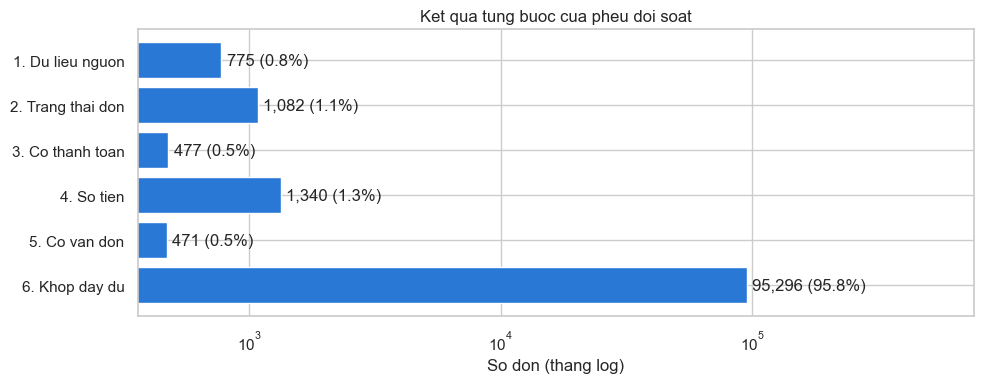

In [20]:
# Buoc 6 - Con lai: du lieu du, trang thai hop le, co thanh toan khop tien, co van don
step6 = apply_step("6. Khop day du", recon["simple_rule"].isna(), "PASS")
assert recon["simple_rule"].notna().all(), "Con don chua duoc phan loai"

funnel_table = pd.DataFrame.from_dict(funnel, orient="index").rename_axis("buoc")
funnel_table["ty_le_pct"] = funnel_table["so_don"] / len(recon) * 100
display(funnel_table)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(funnel_table.index[::-1], funnel_table["so_don"][::-1], color="#2a78d6")
ax.bar_label(bars, labels=[f"{n:,} ({p:.1f}%)" for n, p in zip(funnel_table["so_don"][::-1], funnel_table["ty_le_pct"][::-1])], padding=4)
ax.set_xscale("log")
ax.set_xlim(right=funnel_table["so_don"].max() * 8)
ax.set_xlabel("So don (thang log)")
ax.set_title("Ket qua tung buoc cua pheu doi soat")
plt.tight_layout()
plt.show()

**Nhận định — bước 6 và toàn phễu**
- 95.296 đơn (95,8%) `PASS`, 100% đúng `MATCHED` theo ground truth → không có đơn lỗi nào lọt qua phễu.
- 4.145 đơn (4,2%) cần xử lý: 2.288 `EXCEPTION` (bước 3, 4, 5) và 1.857 `REVIEW` (bước 1, 2). Biểu đồ dùng trục log để thấy được các bước nhỏ; đọc số trên nhãn.

**Quyết định tiếp theo**
- `PASS`: auto-accept, lưu bằng chứng đối soát.
- Exception: xử lý theo mức rủi ro — `MISSING_PAYMENT` → `AMOUNT_MISMATCH` → `MISSING_SHIPMENT`.
- Đo chất lượng rule bằng crosstab với ground truth ở cell dưới.

In [21]:
expected = recon["expected_exception"].fillna("PASS")
comparison = pd.crosstab(expected, recon["simple_rule"])
display(comparison)
agreement = (expected == recon["simple_rule"]).mean()
print(f"Ty le trung khop don gian voi ground truth: {agreement:.2%}")
print("Top amount deltas:")
paid = recon[recon["has_payment"]]
display(paid.loc[paid["payment_delta"].abs().sort_values(ascending=False).head(10).index,
                     ["order_id", "order_amount", "bank_net", "payment_delta", "scenario", "expected_exception"]])

simple_rule,AMOUNT_MISMATCH,MISSING_PAYMENT,MISSING_SHIPMENT,MISSING_SOURCE_EVIDENCE,ORDER_STATUS_REQUIRES_POLICY,PASS
expected_exception,,,,,,
AMOUNT_MISMATCH,977,0,0,0,0,0
MISSING_PAYMENT,0,476,0,0,0,0
MISSING_SHIPMENT,0,0,471,0,0,0
MISSING_SOURCE_EVIDENCE,0,1,0,775,0,0
ORDER_STATUS_REQUIRES_POLICY,0,0,0,0,1082,0
PASS,363,0,0,0,0,95296


Ty le trung khop don gian voi ground truth: 99.63%
Top amount deltas:


,order_id,order_amount,bank_net,payment_delta,scenario,expected_exception
88886,736e1922ae60d0d6a89247b851902527,"7,274.88","7,638.62",363.74,AMOUNT_ERROR,AMOUNT_MISMATCH
51224,ce6d150fb29ada17d2082f4847107665,"1,403.66","1,586.47",182.81,MATCHED,NaN
72953,3dd5626c63f493f8b8f8788c2be24baa,"3,005.06","3,155.31",150.25,AMOUNT_ERROR,AMOUNT_MISMATCH
95708,6d0940a8f5fba47562bb14cd97dfd6da,"2,455.12","2,577.88",122.76,AMOUNT_ERROR,AMOUNT_MISMATCH
277,6e5fe7366a2e1bfbf3257dba0af1267f,287.91,406.92,119.01,MATCHED,NaN
22234,70b742795bc441e94a44a084b6d9ce7a,466.93,578.82,111.89,MATCHED,NaN
26808,94781b7e571ded2ff6f80434f6fe2a43,"1,653.60","1,736.28",82.68,AMOUNT_ERROR,AMOUNT_MISMATCH
4093,d54005052afdbf06d7a1d39cc9e45f92,"1,648.64","1,731.07",82.43,AMOUNT_ERROR,AMOUNT_MISMATCH
34806,cb8da41d3686c19bfd7e97b94097e686,"1,642.11","1,724.22",82.11,AMOUNT_ERROR,AMOUNT_MISMATCH
88999,996c7e73600ad3723e8627ab7bef81e4,587.90,664.43,76.53,MATCHED,NaN


## 5. Đề xuất logic đối soát

### A. Chuẩn hóa và kiểm tra đầu vào
1. Chuẩn hóa encoding, timezone, currency, decimal và tên cột; lưu `source_file`, `ingested_at`, `row_hash`.
2. Kiểm tra uniqueness: `order_id`, `txn_ref`, `tracking_code`; phát hiện duplicate trước khi aggregate.
3. Record lỗi schema không được pass/bỏ qua; thay vào đó đánh dấu đợi nghiệp vụ kiểm tra.
4. Kiểm tra giá trị tiền thiếu hoặc bằng 0 ngay khi ingest: dữ liệu hiện có 775 đơn `order_amount` NaN và 3 giao dịch `credit_amount = 0` → gắn `MISSING_SOURCE_EVIDENCE`, không đưa vào so khớp số tiền.



### B. Tạo khóa liên kết theo thứ tự ưu tiên
1. **Pass 1 - exact match**: `bank.txn_ref/reference -> order_id`, `tracking_code -> OMS.tracking_no`; chỉ chấp nhận matching - unique record. Ưu tiên trường reference có cấu trúc thay vì parse `description` (order_id là chuỗi hex 32 ký tự; regex `\d{8,}` đã làm 0% giao dịch map được). Trên dữ liệu hiện tại Pass 1 map được 100% record.
2. **Pass 2 - constrained match**: nếu thiếu ID, kết hợp currency, amount trong tolerance và cửa sổ ngày **±4 ngày** (P99 độ trễ `txn_date` → `value_date` = 4 ngày; 71 giao dịch trễ > 7 ngày, max 188 ngày → đưa vào review). Không tự động match khi có nhiều ứng viên gần nhau.
3. **Pass 3 - review**: fuzzy/heuristic chỉ tạo candidate và confidence, không tự động ghi nhận là matched nếu confidence thấp/dưới ngưỡng.

### C. Quy tắc nghiệp vụ
- **Thứ tự quyết định** (dừng ở điều kiện đầu tiên đúng):
  1. Thiếu `order_amount` → `MISSING_SOURCE_EVIDENCE`
  2. `order_status` ngoài `delivered`/`shipped` → `ORDER_STATUS_REQUIRES_POLICY`
  3. Không có bank record → `MISSING_PAYMENT`
  4. `abs(delta) > 0.01 BRL` → `AMOUNT_MISMATCH`
  5. Không có vận đơn → `MISSING_SHIPMENT`
  6. Còn lại → `PASS`

  Bước 1–2 phải đứng trước kiểm tra thanh toán/vận chuyển: nếu không, 775 đơn thiếu dữ liệu bị gán `AMOUNT_MISMATCH` và 1.082 đơn chờ policy bị gán `MISSING_SHIPMENT`. Với thứ tự này, rule đơn giản khớp ground truth 99,63%.
- **Prepaid**: so `order_amount` với `bank_net` (hoặc `credit_amount - fee_amount` theo contract); pass khi `abs(delta) <= 0.01 BRL` và có đúng một giao dịch hợp lệ. Không dùng tolerance theo %: lỗi `AMOUNT_ERROR` nhỏ nhất là 1,00 BRL và luôn lệch đúng 5%, nên mọi ngưỡng ≥ 1 BRL hoặc ≥ 5% đều bỏ sót lỗi.
- **COD**: đối chiếu `cod_collected` với số tiền phải thu, `cod_fee` theo biểu phí và remittance với bank credit; cần cho phép settlement trễ trong cửa sổ ngày.
- **Vận chuyển**: kiểm tra có shipment, trạng thái, phí ship, thời điểm picked/delivered; một order có nhiều event cần aggregate theo event mới nhất và lưu lịch sử.
  - Không dùng `delivered_at` của đơn `SHIPPED` để tính thời gian giao: 1.100/1.100 đơn có giờ 00:00:00 (ngày ước tính, không phải sự kiện thật).
  - `picked_at > delivered_at` (30 vận đơn) → `TIMING_MISMATCH`.
- **Nhóm exception**: `MISSING_SOURCE_EVIDENCE`, `ORDER_STATUS_REQUIRES_POLICY`, missing payment / shipment, duplicate, amount mismatch, timing mismatch, orphan record là các nhóm riêng, có reason code và mức độ ưu tiên.

**Giới hạn của dữ liệu benchmark** — các quy tắc sau chưa kiểm chứng được:
- COD và phí ngân hàng: `payment_method` 100% `PREPAID`; `cod_collected`, `cod_fee`, `fee_amount` luôn bằng 0.
- "Đúng một giao dịch": dữ liệu luôn 1 đơn ↔ 1 giao dịch, không có thanh toán nhiều lần.
- Phí ship: OMS không có phí ship kỳ vọng để đối chiếu; chỉ gắn cờ được 336 đơn `ship_fee = 0`.
- Event mới nhất: `tracking_code` unique, mỗi đơn chỉ có 1 event.
- Duplicate / orphan / timing (ngoài 30 ca trên): không có ca nào trong dữ liệu, ground truth không có nhãn.

**Vấn đề mở**: 363 đơn ground truth gắn `MATCHED` nhưng lệch tiền thật (trung vị ~5,8%, tối đa 183 BRL). Không chỉnh được bằng tolerance mà không bỏ sót `AMOUNT_ERROR` → cần nghiệp vụ xác nhận đây là voucher/lãi trả góp (ngoại lệ hợp lệ có reason code riêng) hay lỗi nhãn.

### D. Kết quả và audit
Mỗi kết quả nên có `recon_id`, khóa liên kết, các delta, confidence, rule version, timestamp, input row hashes và reason codes. Chỉ auto-accept ở ngưỡng confidence cao; phần còn lại vào triage queue. Báo cáo hằng ngày gồm precision của auto-match, review rate, giá trị exception và aging của exception. Vì 96,2% đơn là `MATCHED`, đánh giá bằng **precision/recall theo từng reason code**, không dùng accuracy tổng (gán PASS cho tất cả đã đạt ~96%).

### E. Xử lý trạng thái đơn hàng
Không lọc `canceled`, `unavailable`, `invoiced`, `processing`, `created` hoặc `approved` tại bước ingest. Giữ nguyên OMS và tạo `STATUS_PENDING_POLICY` cho các trạng thái chưa có quy tắc được phê duyệt. Engine nên tách ba lớp: **raw ingestion** (giữ dữ liệu), **eligibility policy** (do người nghiệp vụ cấu hình), và **reconciliation decision** (chỉ đối soát khi policy cho phép). Kết quả trước khi có policy nên là `REVIEW`/`PENDING_POLICY`, không phải auto-accept hay tự động loại bỏ.

Lưu ý thứ tự: đơn thiếu dữ liệu nguồn được gán `MISSING_SOURCE_EVIDENCE` trước khi xét trạng thái — ví dụ `unavailable` có 603 đơn `INCOMPLETE_SOURCE` và chỉ 6 đơn `STATUS_PENDING_POLICY`.
